# 05 — Image Preparation and Augmentation (R2)

**Input:** `data/processed/cub_images_cropped.csv` (run `python scripts/prepare_images.py` first)

Checks that the image pipeline worked, shows what augmentation does, and confirms there is no leakage between train, validation and test.

In [1]:
import sys
sys.path.insert(0, "../scripts")

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image

import r2_utils as u
from augmentation import IMAGENET_MEAN, IMAGENET_STD, make_splits, train_transform

u.set_plot_style()
CSV = u.PROCESSED_DIR / "cub_images_cropped.csv"

## 1. Did `prepare_images.py` work?

In [2]:
table = pd.read_csv(CSV)
sizes = [Image.open(u.PROCESSED_DIR / p).size for p in table["cropped_path"]]
modes = {Image.open(u.PROCESSED_DIR / p).mode for p in table["cropped_path"][:500]}

assert len(table) == 11788, "some images are missing"
assert all(min(s) == 256 for s in sizes), "shorter side should be 256 px"
assert modes == {"RGB"}, modes
print("OK: 11,788 cropped RGB images, shorter side 256 px")

OK: 11,788 cropped RGB images, shorter side 256 px


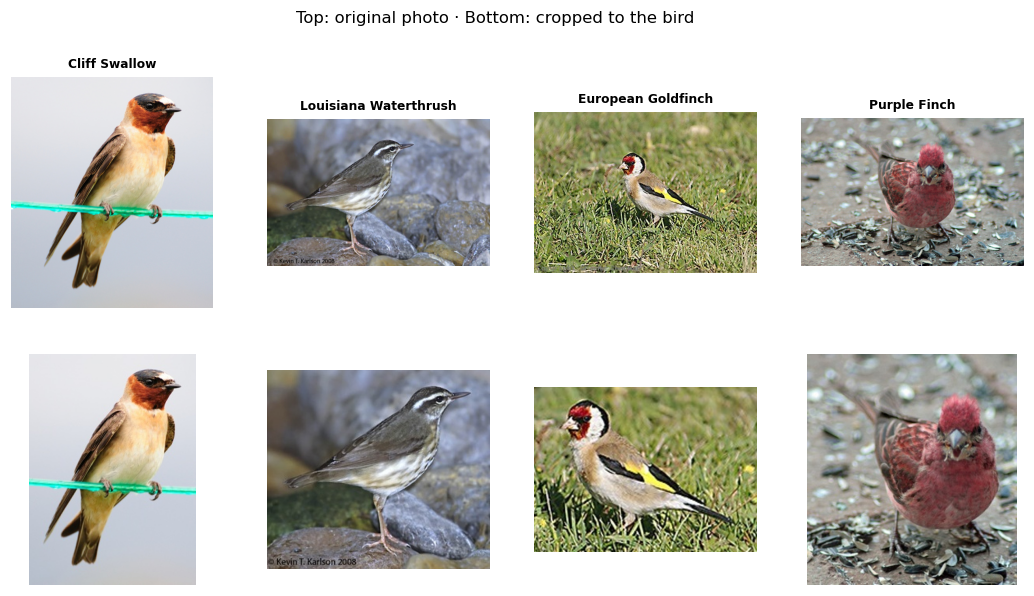

In [3]:
# Before / after for 4 images
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for col, row in enumerate(table.sample(4, random_state=u.RANDOM_STATE).itertuples()):
    axes[0, col].imshow(Image.open(u.RAW_DIR / "images" / row.image_path).convert("RGB"))
    axes[1, col].imshow(Image.open(u.PROCESSED_DIR / row.cropped_path))
    axes[0, col].set_title(row.species, fontsize=8)
    for a in axes[:, col]:
        a.axis("off")
axes[0, 0].set_ylabel("original")
fig.suptitle("Top: original photo · Bottom: cropped to the bird")
u.save_figure(fig, "05_crop_examples")
plt.show()

## 2. Leakage check on the splits

In [4]:
train, val, test = make_splits(CSV)
print(f"train {len(train):,} | val {len(val):,} | test {len(test):,}")

assert not set(train.image_id) & set(val.image_id), "train and val overlap"
assert not set(train.image_id) & set(test.image_id), "train and test overlap"
assert (test["is_train"] == 0).all() and (val["is_train"] == 1).all()
assert train["class_id"].nunique() == val["class_id"].nunique() == 200
print("OK: no overlap, val comes from the official train split, all 200 species in train and val")

train 4,795 | val 1,199 | test 5,794
OK: no overlap, val comes from the official train split, all 200 species in train and val


## 3. What augmentation does to one training image

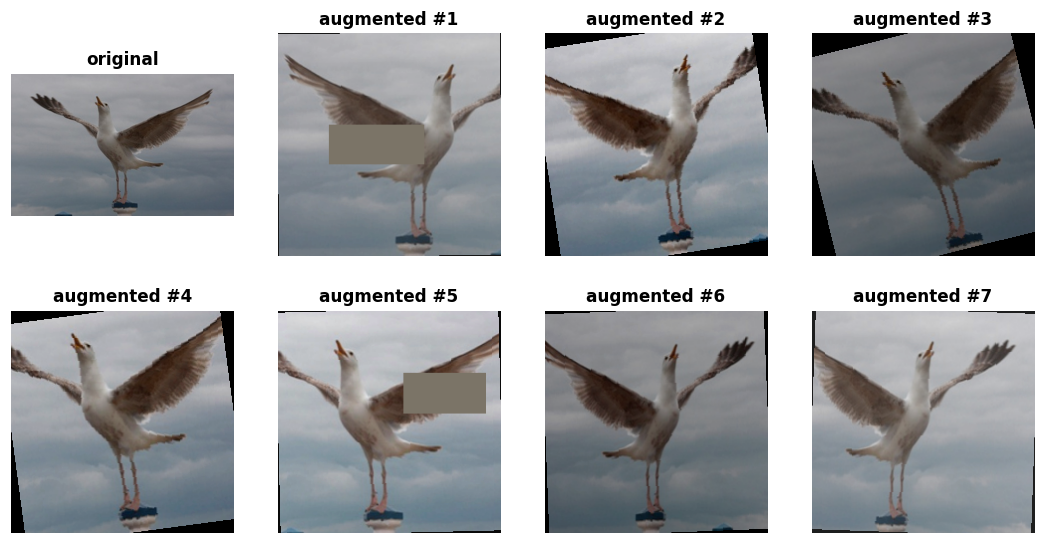

In [5]:
img = Image.open(u.PROCESSED_DIR / train.iloc[0]["cropped_path"]).convert("RGB")
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes[0, 0].imshow(img)
axes[0, 0].set_title("original")
for i, ax in enumerate(axes.flat[1:], start=1):
    x = train_transform(img) * std + mean          # undo normalisation so it can be shown
    ax.imshow(x.permute(1, 2, 0).clamp(0, 1))
    ax.set_title(f"augmented #{i}")
for ax in axes.flat:
    ax.axis("off")
u.save_figure(fig, "05_augmentation_examples")
plt.show()

**Figure** — each time the model sees this photo during training it gets a different random version (crop, flip, small rotation, lighting change, hidden patch). Validation and test images are never changed this way.

> **Decision 9 — Images.** _All 11,788 images are converted to RGB, cropped to their bounding box plus a 10% margin (so bill and tail tips are kept), and resized to 256 px on the shorter side. These fixed steps are applied to train and test alike. With only limited training images per species, the training images ONLY are augmented on the fly with random crop, horizontal flip, ±15° rotation, lighting jitter and random erasing. We use no vertical flip (birds are not upside down) and almost no hue change (colour separates look-alike species, see notebook 02). A validation set (20%, stratified by species) is taken from the training split before augmentation, and the official test split is never augmented, so there is no leakage._